# Data Preparation and Exploratory Analysis

In [ ]:
# This notebook handles data preparation and the Exploratory Data Analysis ##
# Run this notebook first. It creates the processed Parquet files used by 02_recommender_experiment.ipynb.

# Required raw H&M files in data/raw/:
# transactions.csv (or the Kaggle filename transactions_train.csv)
# articles.csv

## Imports and data file paths

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

project_root = Path.cwd().resolve()
if not (project_root / "data" / "raw").exists():
    project_root = project_root.parent
if not (project_root / "data" / "raw").exists():
    raise FileNotFoundError("Could not find the project data directory. Check the notebook location.")

DATA_RAW = project_root / "data" / "raw"
DATA_PROCESSED = project_root / "data" / "processed"
DATA_PROCESSED.mkdir(parents = True, exist_ok=True)

RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(parents = True, exist_ok = True)

TRANSACTIONS_PATH = DATA_RAW / "transactions.csv"
if not TRANSACTIONS_PATH.exists():
    TRANSACTIONS_PATH = DATA_RAW / "transactions_train.csv"

ARTICLES_PATH = DATA_RAW / "articles.csv"

if not TRANSACTIONS_PATH.exists():
    raise FileNotFoundError("Missing transactions.csv / transactions_train.csv")
if not ARTICLES_PATH.exists():
    raise FileNotFoundError("Missing articles.csv")


## Load and filter data

In [ ]:
# Loading in memory-conscious data types
transaction_dtypes = {
    "customer_id": "string",
    "article_id": "string",
    "price": "float32",
    "sales_channel_id": "int8",
}

transactions = pd.read_csv(
    TRANSACTIONS_PATH,
    dtype=transaction_dtypes, 
    parse_dates=["t_dat"],
    )

print(f"Transactions: {len(transactions):,}")   # 31,788,324
print(f"Customers: {transactions['customer_id'].nunique():,}")  # 1,362,281
print(f"Articles: {transactions['article_id'].nunique():,}")   # 104,547
print(
    f"Transaction period: {transactions['t_dat'].min().date()} "   # 2018-09-20 to 2020-09-22
    f"to {transactions['t_dat'].max().date()}"
)

Transactions: 31,788,324
Customers: 1,362,281
Articles: 104,547
Transaction period: 2018-09-20 to 2020-09-22


## Online transactions

In [ ]:
# Filtering online transactions
transactions_online = transactions[transactions["sales_channel_id"] == 2].copy()
# Remove sales_channel_id
transactions_online = transactions_online.drop(columns=["sales_channel_id"])

print(f"Online transactions: {len(transactions_online):,}")                            # 22,379,862
print(f"Share online: {len(transactions_online) / len(transactions):.1%}")             # 70.4%
print(f"Online customers: {transactions_online['customer_id'].nunique():,}")           # 1,108,418
print(f"Articles purchased online: {transactions_online['article_id'].nunique():,}")   # 98,322

# Saving the online transactions to processed data directory
transactions_online.to_parquet(
    DATA_PROCESSED / "transactions_online.parquet",
      index=False)

TRANSACTIONS_ONLINE_PATH = DATA_PROCESSED / "transactions_online.parquet"

Online transactions: 22,379,862
Share online: 70.4%
Online customers: 1,108,418
Articles purchased online: 98,322


In [5]:
# Inspecting the date range of online transactions
transactions_online["t_dat"].min(), transactions_online["t_dat"].max()

transactions_online["t_dat"].describe()

count                      22379862
mean     2019-09-18 09:04:09.935159
min             2018-09-20 00:00:00
25%             2019-03-31 00:00:00
50%             2019-09-03 00:00:00
75%             2020-04-03 00:00:00
max             2020-09-22 00:00:00
Name: t_dat, dtype: object

## Constructing shopping episodes

In [ ]:
# Constructing customer-day shopping episodes #
# Shopping episode definition
# episode = customer + date 

episodes = (
    transactions_online
    .groupby(["customer_id", "t_dat"])["article_id"]
    .apply(list)
    .reset_index(name="articles")
)

episodes["episode_size"] = episodes["articles"].str.len()

# Count for unique articles for later analysis:
episodes["unique_articles"] = episodes["articles"].apply(
    lambda x: len(set(x)))


print(f"All online shopping episodes: {len(episodes):,}")   # 5,491,707
print(episodes["episode_size"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
))


All online shopping episodes: 5,491,707
count    5.491707e+06
mean     4.075210e+00
std      4.189701e+00
min      1.000000e+00
50%      3.000000e+00
75%      5.000000e+00
90%      9.000000e+00
95%      1.200000e+01
99%      2.000000e+01
max      3.360000e+02
Name: episode_size, dtype: float64


In [7]:
# For inspection
#episodes.head()
#episodes.info()
#episodes.describe()

In [ ]:
# How many shopping episodes have more than one article?
multiple_article_episodes = episodes[episodes["episode_size"] >= 2]

print(
    f"Multi-item episodes: "
    f"{len(multiple_article_episodes):,} "
    f"({len(multiple_article_episodes) / len(episodes):.1%})"  # 4,137,260 (75.3%)
)

Multi-item episodes: 4,137,260 (75.3%)


In [9]:
# Saving the shopping episode items with article metadata to processed data directory
multiple_article_episodes = multiple_article_episodes.sort_values("t_dat").reset_index(drop=True)
multiple_article_episodes.to_parquet(DATA_PROCESSED / "multi-item_shopping_episodes.parquet", index=False)

## Episode size Distribution plot

99th percentile of episode size: 20


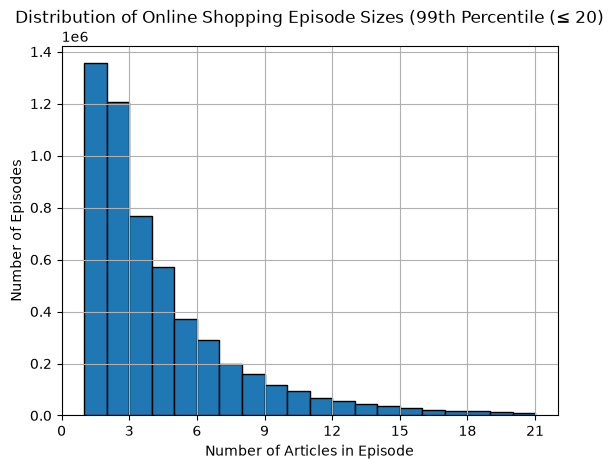

In [11]:
# Plot of episode size distribution (histogram)
upper_limit = int(episodes["episode_size"].quantile(0.99))

print(f"99th percentile of episode size: {upper_limit}")

episodes[
    episodes["episode_size"] <= upper_limit
]["episode_size"].hist(
    bins=range(1, upper_limit + 2),
    edgecolor="black"
)
plt.xlabel("Number of Articles in Episode")
plt.ylabel("Number of Episodes")
plt.title(f"Distribution of Online Shopping Episode Sizes (99th Percentile (≤ {upper_limit})")
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))

plt.show()

## Article metadata and episode characteristics

In [12]:
## Article metadata and episode characteristics ##

articles = pd.read_csv(ARTICLES_PATH, dtype={"article_id": "string"})

# Compact article table
article_features = articles[
    [
    "article_id",
    "product_code",
    "product_type_no",
    "product_group_name",
    "colour_group_code",
    "department_no",
    "graphical_appearance_name",
    "section_no",
    "garment_group_no",
    ]
].copy()

# Saving processed article dataset to processed data directory, only including the 9 selected features (article_id, product_code, product_type_no, 
# # product_group_name, colour_group_code, department_no, graphical_appearance_name, 
# section_no, garment_group_no) 
article_features.to_parquet(
    DATA_PROCESSED / "article_features.parquet",
      index=False)



In [13]:
# Are items grouped?
episode_items = (
    multiple_article_episodes
    .explode("articles")
    .rename(columns={"articles": "article_id"})
)

# merging article metadata
episode_items = episode_items.merge(
    article_features,
    on="article_id",
    how="left"
)

In [14]:
# Products within an episode sharing attributes?
group_stats = (
    episode_items
    .groupby(["customer_id", "t_dat"])
    .agg(
        episode_size=("article_id", "count"),
        unique_articles=("article_id", "nunique"),
        n_product_codes=("product_code", "nunique"),
        n_product_types=("product_type_no", "nunique"),
        n_product_groups=("product_group_name", "nunique"),
        n_colours=("colour_group_code", "nunique"),
        n_departments=("department_no", "nunique"),
        n_graphical_appearances=("graphical_appearance_name", "nunique"),
        n_sections=("section_no", "nunique"),
        n_garment_groups=("garment_group_no", "nunique"),
    )
    .reset_index()
)

In [15]:
# Characteristics of multi-item shopping episodes - table
characteristic_columns = {
    "Items per episode": "episode_size",
    "Unique articles": "unique_articles",
    "Unique product codes": "n_product_codes",
    "Unique product types": "n_product_types",
    "Unique product groups": "n_product_groups",
    "Unique colours": "n_colours",
    "Unique departments": "n_departments",
    "Unique graphical appearances": "n_graphical_appearances",
    "Unique sections": "n_sections",
    "Unique garment groups": "n_garment_groups",
}

source_columns = {
    "Unique articles": "article_id",
    "Unique product codes": "product_code",
    "Unique product types": "product_type_no",
    "Unique product groups": "product_group_name",
    "Unique colours": "colour_group_code",
    "Unique departments": "department_no",
    "Unique graphical appearances": "graphical_appearance_name",
    "Unique sections": "section_no",
    "Unique garment groups": "garment_group_no",
}

rows = []
for label, col in characteristic_columns.items():
    s = group_stats[col]
    rows.append({
        "Episode characteristic": label,
        "Mean": s.mean(),
        "SD": s.std(),
        "25th percentile": s.quantile(0.25),
        "Median": s.median(),
        "75th percentile": s.quantile(0.75),
        "Number of distinct values": (
            episode_items[source_columns[label]].nunique(dropna=True)
            if label in source_columns
            else np.nan
        ),
    })

table3 = pd.DataFrame(rows)
table3

,Episode characteristic,Mean,SD,25th percentile,Median,75th percentile,Number of distinct values
0,Items per episode,5.081966,4.380720,2.0,4.0,6.0,NaN
1,Unique articles,4.388586,3.558084,2.0,3.0,5.0,97928.0
2,Unique product codes,4.002851,3.208772,2.0,3.0,5.0,44441.0
3,Unique product types,2.763357,1.793734,2.0,2.0,3.0,129.0
4,Unique product groups,1.984528,1.024193,1.0,2.0,2.0,19.0
5,Unique colours,2.975079,1.896702,2.0,2.0,4.0,50.0
6,Unique departments,3.071092,2.235606,2.0,2.0,4.0,298.0
7,Unique graphical appearances,2.180507,1.196572,1.0,2.0,3.0,30.0
8,Unique sections,2.546565,1.612705,1.0,2.0,3.0,57.0
9,Unique garment groups,2.488851,1.547179,1.0,2.0,3.0,21.0


## Within-episode concentrations

In [16]:
## Within-episode concentrations ##

def concentration(n_unique, episode_size):
    return 1 - ((n_unique -1) / (episode_size - 1))

# Grouping measures 
# values close to 1 indicate that the items in the episode are similar, 
# while values close to 0 indicate that the items are diverse.

group_stats["unique_article_concentration"] = concentration(
    group_stats["unique_articles"], group_stats["episode_size"]
)
group_stats["product_code_concentration"] = concentration(
    group_stats["n_product_codes"], group_stats["episode_size"]
)
group_stats["product_type_concentration"] = concentration(
    group_stats["n_product_types"], group_stats["episode_size"]
)
group_stats["product_group_concentration"] = concentration(
    group_stats["n_product_groups"], group_stats["episode_size"]
)
group_stats["colour_concentration"] = concentration(
    group_stats["n_colours"], group_stats["episode_size"]
)
group_stats["department_concentration"] = concentration(
    group_stats["n_departments"], group_stats["episode_size"]
)
group_stats["graphical_appearance_concentration"] = concentration(
    group_stats["n_graphical_appearances"], group_stats["episode_size"]
)
group_stats["section_concentration"] = concentration(
    group_stats["n_sections"], group_stats["episode_size"]
)
group_stats["garment_group_concentration"] = concentration(
    group_stats["n_garment_groups"], group_stats["episode_size"]
)

CONCENTRATION_COLUMNS = [
    "unique_article_concentration",
    "product_code_concentration",
    "product_type_concentration",
    "product_group_concentration",
    "colour_concentration",
    "department_concentration",
    "graphical_appearance_concentration",
    "section_concentration",
    "garment_group_concentration",
]

In [17]:
# Within-episode concentration table #
table4 = (
    group_stats[CONCENTRATION_COLUMNS]
    .describe(percentiles=[0.25, 0.50, 0.75])
    .T[["mean", "std", "25%", "50%", "75%"]]
    .rename(columns={
        "mean": "Mean",
        "std": "SD",
        "25%": "25th percentile",
        "50%": "Median",
        "75%": "75th percentile",
    })
)
table4

,Mean,SD,25th percentile,Median,75th percentile
unique_article_concentration,0.152644,0.279325,0.000000,0.000000,0.200000
product_code_concentration,0.248854,0.331058,0.000000,0.000000,0.500000
product_type_concentration,0.507620,0.370193,0.000000,0.500000,0.833333
product_group_concentration,0.698827,0.334192,0.500000,0.800000,1.000000
colour_concentration,0.448431,0.364573,0.000000,0.500000,0.714286
department_concentration,0.453610,0.374515,0.000000,0.500000,0.750000
graphical_appearance_concentration,0.649759,0.345247,0.500000,0.714286,1.000000
section_concentration,0.569913,0.364058,0.333333,0.600000,1.000000
garment_group_concentration,0.583066,0.363222,0.333333,0.625000,1.000000


## Episode types

In [18]:
## Mutually exclusive episode types ##

# No narrow grouping: every article and product code is different
group_stats["no_narrow_grouping"] = (
    (group_stats["unique_articles"] == group_stats["episode_size"]) &
    (group_stats["n_product_codes"] == group_stats["unique_articles"])
)

# Exact duplicate purchases: at least one identical article_id occurs more than once
group_stats["has_exact_duplicates"] = (
    group_stats["unique_articles"] < group_stats["episode_size"]
)

# Related variants but no exact duplicates: all article IDs are unique,
# but at least two share the same product code
group_stats["has_variant_grouping"] = (
    (group_stats["unique_articles"] == group_stats["episode_size"]) &
    (group_stats["n_product_codes"] < group_stats["unique_articles"])
)

# Both exact duplicates and product-family grouping
group_stats["has_duplicates_and_grouping"] = (
    (group_stats["unique_articles"] < group_stats["episode_size"]) &
    (group_stats["n_product_codes"] < group_stats["unique_articles"])
)

conditions = [
    group_stats["has_duplicates_and_grouping"],
    group_stats["has_exact_duplicates"] & ~group_stats["has_duplicates_and_grouping"],
    group_stats["has_variant_grouping"],
    group_stats["no_narrow_grouping"],
]

choices = [
    "Exact duplicates + additional product-code grouping",
    "Exact duplicates only",
    "Product-code grouping without exact duplicates",
    "No narrow grouping",
]

group_stats["episode_type"] = np.select(
    conditions,
    choices,
    default = "Unclassified",
)

assert (group_stats["episode_type"] != "Unclassified").all() # Check that all episodes have a type

In [19]:
# Episode type frequencies table #
episode_type_order = [
    "No narrow grouping",
    "Product-code grouping without exact duplicates",
    "Exact duplicates only",
    "Exact duplicates + additional product-code grouping",
]

table5 = (
    group_stats["episode_type"]
    .value_counts(normalize=True)
    .reindex(episode_type_order)
    .mul(100)
    .rename("Share (%)")
    .to_frame()
)

table5

,Share (%)
episode_type,
No narrow grouping,51.723919
Product-code grouping without exact duplicates,16.324186
Exact duplicates only,22.103856
Exact duplicates + additional product-code grouping,9.848040


In [20]:
## Grouping by product attribute ##
strong_grouping = (
    group_stats[CONCENTRATION_COLUMNS]
    .ge(0.5)
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("Episodes with concentration ≥ 0.5 (%)")
    .to_frame()
)

strong_grouping

,Episodes with concentration ≥ 0.5 (%)
product_group_concentration,82.724170
graphical_appearance_concentration,78.282076
garment_group_concentration,68.962550
section_concentration,67.396852
product_type_concentration,59.652427
colour_concentration,52.362796
department_concentration,50.689853
product_code_concentration,25.098278
unique_article_concentration,14.981485


In [21]:
# Saving processed episode statistics
group_stats.to_parquet(
    DATA_PROCESSED / "group_stats.parquet",
    index = False,
)

In [ ]:
articles_purchased_online = transactions_online["article_id"].unique()
print(f"Number of unique articles purchased online: {len(articles_purchased_online):,}") # 98,322

Number of unique articles purchased online: 98,322


In [23]:
# Get article IDs that occur in online transactions
online_article_ids = transactions_online["article_id"].unique()

# Keep only articles involved in online transactions
articles_online = articles[
    articles["article_id"].isin(online_article_ids)
].copy()

# Product attributes
product_attributes = [
    "product_code",
    "product_type_no",
    "product_group_name",
    "colour_group_code",
    "department_no",
    "graphical_appearance_name",
    "section_no",
    "garment_group_no"
]

# Number of unique categories for each attribute
unique_categories = articles_online[product_attributes].nunique()

print(unique_categories)

product_code                 44605
product_type_no                129
product_group_name              19
colour_group_code               50
department_no                  298
graphical_appearance_name       30
section_no                      57
garment_group_no                21
dtype: int64


## Saving EDA tables

In [24]:
# Saving and exporting EDA tables to results
table3.to_csv(
    RESULTS_DIR / "table_03_episode_characteristics.csv",
    index=False,
)

concentration_labels = {
    "unique_article_concentration": "Article ID",
    "product_code_concentration": "Product code",
    "product_type_concentration": "Product type",
    "product_group_concentration": "Product group",
    "colour_concentration": "Colour",
    "department_concentration": "Department",
    "graphical_appearance_concentration": "Graphical appearance",
    "section_concentration": "Section",
    "garment_group_concentration": "Garment group",
}
table4_export = (
    table4.rename(index=concentration_labels)
    .rename_axis("Attribute")
    .reset_index()
)
table4_export.to_csv(
    RESULTS_DIR / "table_04_within_episode_concentration.csv",
    index=False,
)

table5_export = (
    table5.rename_axis("Episode type")
    .reset_index()
)
table5_export.to_csv(
    RESULTS_DIR / "table_05_episode_type_frequencies.csv",
    index=False,
)

table6_export = (
    strong_grouping.rename(index=concentration_labels)
    .rename_axis("Attribute")
    .reset_index()
)
table6_export.to_csv(
    RESULTS_DIR / "table_06_strong_grouping.csv",
    index=False,
)